In [7]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [8]:
# Sample dataset: Car specifications
car_dict = {
    'Horsepower': [110, 130, 150, 180, 210, 250, 290, 330],
    'Top_Speed':  [120, 130, 140, 150, 160, 170, 185, 200],
    'Price_K':    [18,  22,  26,  32,  40,  50,  65,  80],
    'MPG':        [35,  32,  28,  25,  22,  19,  16,  14]
}
cars_df = pd.DataFrame(car_dict)
print("--- Initial Dataset ---")
print(cars_df)

--- Initial Dataset ---
   Horsepower  Top_Speed  Price_K  MPG
0         110        120       18   35
1         130        130       22   32
2         150        140       26   28
3         180        150       32   25
4         210        160       40   22
5         250        170       50   19
6         290        185       65   16
7         330        200       80   14


In [9]:
# Overview of the dataset
print("\n--- Data Dimensions ---")
print(cars_df.shape)
print("\n--- Feature Names ---")
print(cars_df.columns.tolist())
print("\n--- Data Info ---")
cars_df.info()
print("\n--- Descriptive Statistics ---")
print(cars_df.describe())


--- Data Dimensions ---
(8, 4)

--- Feature Names ---
['Horsepower', 'Top_Speed', 'Price_K', 'MPG']

--- Data Info ---
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Horsepower  8 non-null      int64
 1   Top_Speed   8 non-null      int64
 2   Price_K     8 non-null      int64
 3   MPG         8 non-null      int64
dtypes: int64(4)
memory usage: 388.0 bytes

--- Descriptive Statistics ---
       Horsepower   Top_Speed    Price_K        MPG
count    8.000000    8.000000   8.000000   8.000000
mean   206.250000  156.875000  41.625000  23.875000
std     78.547074   27.377976  21.947584   7.510707
min    110.000000  120.000000  18.000000  14.000000
25%    145.000000  137.500000  25.000000  18.250000
50%    195.000000  155.000000  36.000000  23.500000
75%    260.000000  173.750000  53.750000  29.000000
max    330.000000  200.000000  80.000000  35.000000


In [10]:
# Isolate features for dimensionality reduction
features = cars_df[['Horsepower', 'Top_Speed', 'Price_K', 'MPG']]
print("\nSelected features for PCA:")
print(features)


Selected features for PCA:
   Horsepower  Top_Speed  Price_K  MPG
0         110        120       18   35
1         130        130       22   32
2         150        140       26   28
3         180        150       32   25
4         210        160       40   22
5         250        170       50   19
6         290        185       65   16
7         330        200       80   14


In [11]:
# Scale the data (Mean=0, Variance=1) so all features weight equally
std_scaler = StandardScaler()
scaled_array = std_scaler.fit_transform(features)
scaled_df = pd.DataFrame(scaled_array, columns=features.columns)

print("\nData after standardization:")
print(scaled_df)


Data after standardization:
   Horsepower  Top_Speed   Price_K       MPG
0   -1.309986  -1.439881 -1.150750  1.583490
1   -1.037781  -1.049405 -0.955914  1.156481
2   -0.765576  -0.658929 -0.761078  0.587137
3   -0.357269  -0.268452 -0.468824  0.160128
4    0.051038   0.122024 -0.079152 -0.266880
5    0.595448   0.512500  0.407938 -0.693889
6    1.139858   1.098214  1.138573 -1.120897
7    1.684268   1.683929  1.869208 -1.405569


In [12]:
# Initialize and fit the PCA model
pca_model = PCA()
pca_transformed = pca_model.fit_transform(scaled_df)

print("\nData after PCA transformation:")
print(pd.DataFrame(pca_transformed, columns=['PrinComp1', 'PrinComp2', 'PrinComp3', 'PrinComp4']))


Data after PCA transformation:
   PrinComp1  PrinComp2  PrinComp3  PrinComp4
0  -2.741862   0.317690  -0.046940   0.007125
1  -2.099593   0.143938   0.013004  -0.016805
2  -1.386628  -0.133021   0.056550   0.025152
3  -0.627454  -0.224058   0.031547  -0.015791
4   0.180196  -0.249558   0.014796  -0.004036
5   1.104751  -0.192343  -0.086901  -0.009294
6   2.248679   0.013934  -0.028451   0.023414
7   3.321911   0.323418   0.046396  -0.009764


In [13]:
# Check variance captured by each component
var_ratio = pca_model.explained_variance_ratio_
print("\nVariance explained by each principal component:")
for idx, var in enumerate(var_ratio):
    print(f"Component {idx+1}: {var:.4f} ({var * 100:.2f}%)")


Variance explained by each principal component:
Component 1: 0.9871 (98.71%)
Component 2: 0.0123 (1.23%)
Component 3: 0.0005 (0.05%)
Component 4: 0.0001 (0.01%)


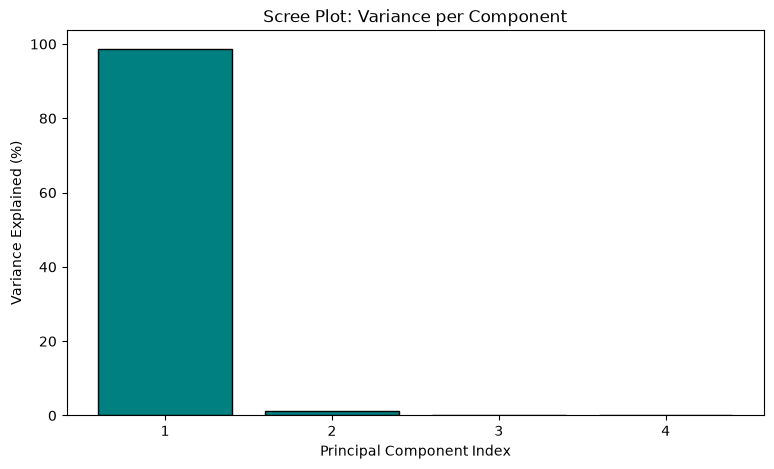

In [14]:
# Scree Plot: Bar chart of explained variance
comp_range = range(1, len(var_ratio) + 1)
plt.figure(figsize=(9, 5))
plt.bar(comp_range, var_ratio * 100, color='teal', edgecolor='black')
plt.xlabel('Principal Component Index')
plt.ylabel('Variance Explained (%)')
plt.title('Scree Plot: Variance per Component')
plt.xticks(comp_range)
plt.show()

In [15]:
# Calculate cumulative variance progression
cum_var = np.cumsum(var_ratio)
print("\nCumulative variance progression:")
for idx, var in enumerate(cum_var):
    print(f"Up to Component {idx+1}: {var * 100:.2f}%")


Cumulative variance progression:
Up to Component 1: 98.71%
Up to Component 2: 99.94%
Up to Component 3: 99.99%
Up to Component 4: 100.00%


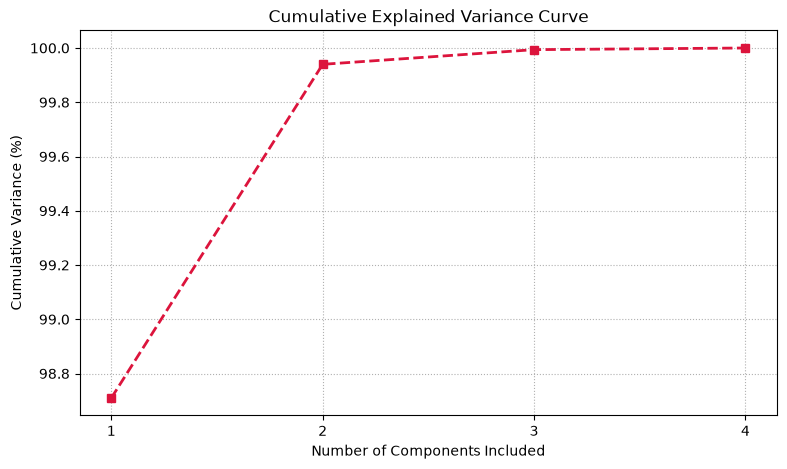

In [16]:
# Line plot representing cumulative variance
plt.figure(figsize=(9, 5))
plt.plot(comp_range, cum_var * 100, marker='s', color='crimson', linestyle='--', linewidth=2)
plt.xlabel('Number of Components Included')
plt.ylabel('Cumulative Variance (%)')
plt.title('Cumulative Explained Variance Curve')
plt.xticks(comp_range)
plt.grid(True, linestyle=':')
plt.show()

In [17]:
# Reduce dimensionality to exactly 2 components for 2D visualization
pca_2 = PCA(n_components=2)
reduced_data = pca_2.fit_transform(scaled_df)

reduced_df = pd.DataFrame(reduced_data, columns=['PrinComp1', 'PrinComp2'])
print("\nReduced 2D Data:")
print(reduced_df)


Reduced 2D Data:
   PrinComp1  PrinComp2
0  -2.741862   0.317690
1  -2.099593   0.143938
2  -1.386628  -0.133021
3  -0.627454  -0.224058
4   0.180196  -0.249558
5   1.104751  -0.192343
6   2.248679   0.013934
7   3.321911   0.323418


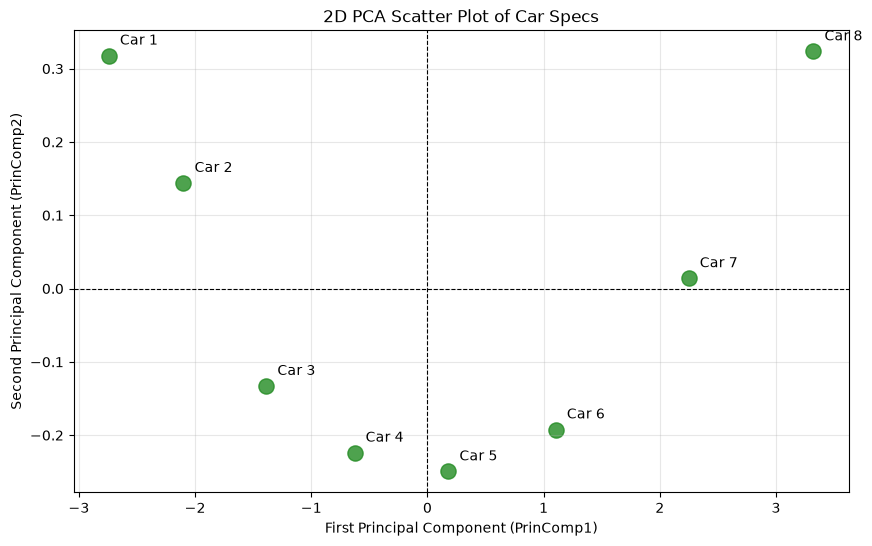

In [18]:
# Scatter plot visualization of the 2D representation
plt.figure(figsize=(10, 6))
plt.scatter(reduced_df['PrinComp1'], reduced_df['PrinComp2'], color='forestgreen', s=120, alpha=0.8)

for idx in range(len(reduced_df)):
    plt.annotate(f'Car {idx+1}', (reduced_df['PrinComp1'][idx], reduced_df['PrinComp2'][idx]), xytext=(8, 8), textcoords='offset points')

plt.xlabel('First Principal Component (PrinComp1)')
plt.ylabel('Second Principal Component (PrinComp2)')
plt.title('2D PCA Scatter Plot of Car Specs')
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.grid(True, alpha=0.3)
plt.show()

In [19]:
# Examine how original features contribute to the principal components
loadings = pd.DataFrame(
    pca_model.components_,
    columns=features.columns,
    index=['PC1', 'PC2', 'PC3', 'PC4']
)
print("\nComponent Loadings (Feature Weights):")
print(loadings)


Component Loadings (Feature Weights):
     Horsepower  Top_Speed   Price_K       MPG
PC1    0.502788   0.502894  0.497600 -0.496685
PC2    0.126211  -0.075705  0.672741  0.725092
PC3   -0.684773   0.714589  0.084714  0.115204
PC4   -0.512211  -0.480343  0.540959 -0.462897


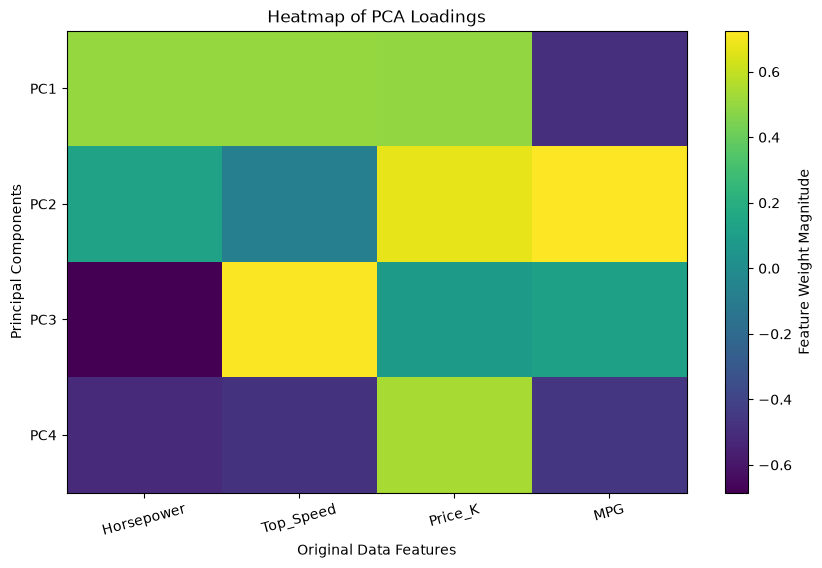

In [20]:
# Heatmap visualization of the feature loadings
plt.figure(figsize=(10, 6))
plt.imshow(loadings, cmap='viridis', aspect='auto')
plt.colorbar(label='Feature Weight Magnitude')
plt.xticks(range(len(features.columns)), features.columns, rotation=15)
plt.yticks(range(len(loadings)), loadings.index)
plt.xlabel('Original Data Features')
plt.ylabel('Principal Components')
plt.title('Heatmap of PCA Loadings')
plt.show()

In [27]:
# %%
# Final Summary of Dimensionality Reduction
print("\n" + "="*45)
print("         CAR DATA COMPRESSION SUMMARY")
print("="*45)
print(f"Initial Specs Count               : {features.shape[1]} columns")
print(f"Reduced Model Complexity          : 2 columns")
print("-" * 45)
print(f"[*] Component 1 Explanatory Power : {var_ratio[0] * 100:.2f}%")
print(f"[*] Component 2 Explanatory Power : {var_ratio[1] * 100:.2f}%")
print("-" * 45)
print(f"OVERALL INFORMATION RETAINED      : {(var_ratio[0] + var_ratio[1]) * 100:.2f}%")
print("="*45)


         CAR DATA COMPRESSION SUMMARY
Initial Specs Count               : 4 columns
Reduced Model Complexity          : 2 columns
---------------------------------------------
[*] Component 1 Explanatory Power : 98.71%
[*] Component 2 Explanatory Power : 1.23%
---------------------------------------------
OVERALL INFORMATION RETAINED      : 99.94%
